# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import numpy as np
import pandas as pd

brut = pd.read_csv("donnees/consommation_brut.csv")
print(brut.shape)
print(brut.dtypes)
print(brut.isna().sum())
print(brut.duplicated().sum())

(300, 4)
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64
12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
brut["quartier"].nunique()

43

**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
conversion = pd.to_numeric(brut["kwh"], errors="coerce")
brut.loc[conversion.isna() & brut["kwh"].notna(), "kwh"]

0      184410 kWh
4      206280 kWh
9      215140 kWh
13        251 900
21     274520 kWh
27     301740 kWh
36     233010 kWh
43     155930 kWh
51     212510 kWh
53     424110 kWh
55     299610 kWh
58        373 880
59     333670 kWh
62     597730 kWh
66     456060 kWh
69     495020 kWh
72        409 300
82        556 070
88     260360 kWh
89     260360 kWh
104    347870 kWh
105       408 780
109       364 090
116    243160 kWh
138       154 720
139       154 720
154       233 700
171       253 300
182    385840 kWh
190    445270 kWh
194       337 810
195       366 390
204       154 740
207    170420 kWh
213    201690 kWh
214    201690 kWh
226     81370 kWh
228    139470 kWh
229     77670 kWh
230    139230 kWh
231    139230 kWh
235       121 240
237    160110 kWh
242       105 830
260    163010 kWh
264    198720 kWh
271       281 240
273       104 640
277    166700 kWh
284        73 110
292       171 160
297    187230 kWh
Name: kwh, dtype: str

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.copy()
propre["kwh"] = propre["kwh"].str.replace(r"\D", "", regex=True)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")
propre["kwh"].isna().sum()

np.int64(9)

**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
quartiers = pd.read_csv("donnees/quartiers.csv")
officiels = {nom.lower(): nom for nom in quartiers["quartier"]}

propre["quartier"] = propre["quartier"].str.strip().str.lower().map(officiels)
print(propre["quartier"].isna().sum())
print(propre["quartier"].nunique())

0
12


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
propre = propre.drop_duplicates()
propre = propre.dropna(subset=["kwh"])
propre.shape

(279, 4)

**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
mediane = propre.groupby("quartier")["kwh"].transform("median")
trop_grands = propre["kwh"] > 3 * mediane
print(propre.loc[trop_grands])

propre["kwh"] = np.where(trop_grands, propre["kwh"] / 10, propre["kwh"])
propre["kwh"] = propre["kwh"].round(2)
propre["kwh"].max()

        mois        quartier        kwh  heures_courant
90   2025-02       Delmas 33  3602600.0            10.1
140  2025-02       Delmas 75  2012700.0            11.1
200  2024-02  Morne Calvaire  1439200.0            11.4
251  2024-01          Rue 15   997700.0             5.9


np.float64(742780.0)

**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
propre = propre.reset_index(drop=True)
reference = pd.read_csv("donnees/consommation.csv")

cles = ["mois", "quartier"]
a = propre.sort_values(cles).reset_index(drop=True)
b = (
    reference[propre.columns]
    .merge(propre[cles], on=cles)
    .sort_values(cles)
    .reset_index(drop=True)
)

print(a.shape, b.shape)
print(a.astype(b.dtypes).equals(b))

(279, 4) (279, 4)
True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
base = propre.merge(quartiers, on="quartier", how="left")
print(len(propre), len(base))

base["kwh_par_abonne"] = (base["kwh"] / base["abonnes"]).round(1)
base["annee"] = pd.to_datetime(base["mois"]).dt.year

base[(base["quartier"] == "Bas-Peu-de-Chose") & (base["mois"] == "2024-01")]

279 279


,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee
0,2024-01,Bas-Peu-de-Chose,184410.0,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
meteo = pd.read_csv("donnees/meteo.csv")
avec_meteo = base.merge(meteo, on=["mois", "commune"], how="left")
print(len(base), len(avec_meteo))
print(avec_meteo["temperature_c"].isna().sum())

279 279
0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)
pd.read_csv("donnees/consommation_propre.csv").shape

(279, 11)

## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

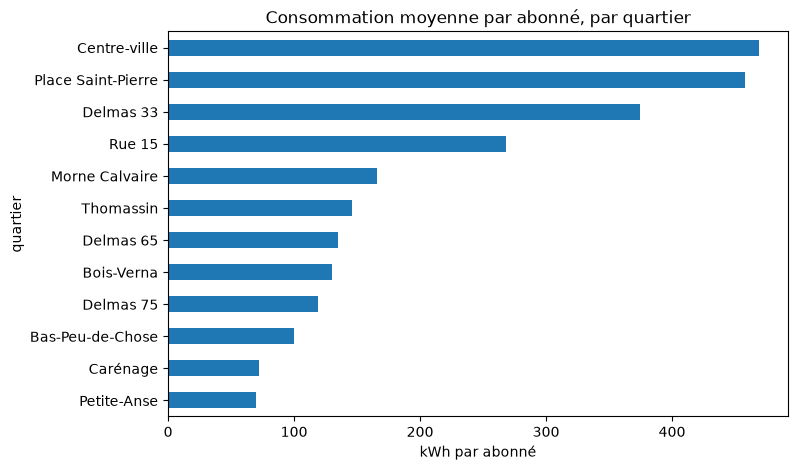

In [20]:
classement.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Consommation moyenne par abonné, par quartier")
plt.xlabel("kWh par abonné")
plt.show()

**Ce qu'on en conclut :**

Le Centre-ville (468,7 kWh), la Place Saint-Pierre (458,3 kWh) et Delmas 33 dominent le classement. Les quartiers commerciaux affichent une consommation par abonné (393,2 kWh) nettement supérieure à celle des zones résidentielles (117,4 kWh).

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

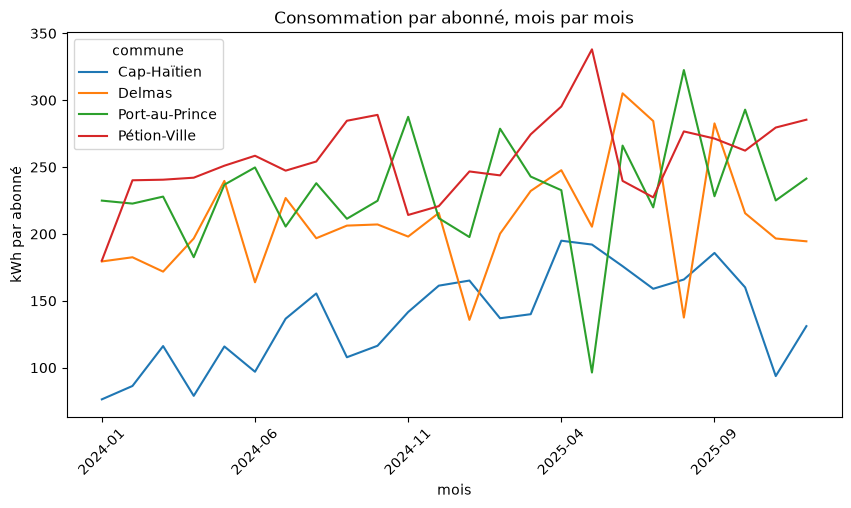

In [21]:
courbe = avec_meteo.groupby(["mois", "commune"])["kwh_par_abonne"].mean().unstack()

courbe.plot(figsize=(10, 5))
plt.title("Consommation par abonné, mois par mois")
plt.ylabel("kWh par abonné")
plt.xticks(rotation=45)
plt.show()

**Ce qu'on en conclut :**

Cap-Haïtien affiche la plus forte hausse en volume sur les deux ans (+22,4 %, passant de 4,59 à 5,62 millions de kWh), tandis que Delmas stagne (+1,1 %). L'évolution mensuelle par abonné montre des fluctuations importantes et des disparités marquées selon les communes.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

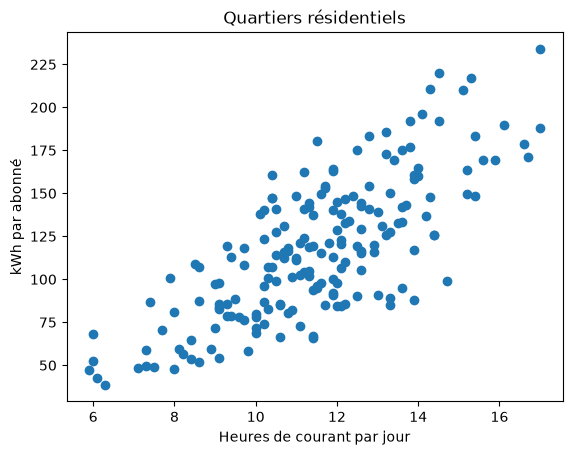

0.76
-0.15


In [17]:
residentiel = avec_meteo[avec_meteo["type"] == "Résidentiel"]

plt.scatter(residentiel["heures_courant"], residentiel["kwh_par_abonne"])
plt.xlabel("Heures de courant par jour")
plt.ylabel("kWh par abonné")
plt.title("Quartiers résidentiels")
plt.show()

print(residentiel["kwh_par_abonne"].corr(residentiel["heures_courant"]).round(2))
print(residentiel["kwh_par_abonne"].corr(residentiel["temperature_c"]).round(2))

**Ce qu'on en conclut :**

La consommation suit les heures de courant (forte corrélation positive de 0,76), tandis qu'elle ne suit pas la chaleur (corrélation négative de -0,15 avec la température). Les abonnés consomment davantage lorsqu'ils ont accès à l'électricité, indépendamment des variations de température extérieure.

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

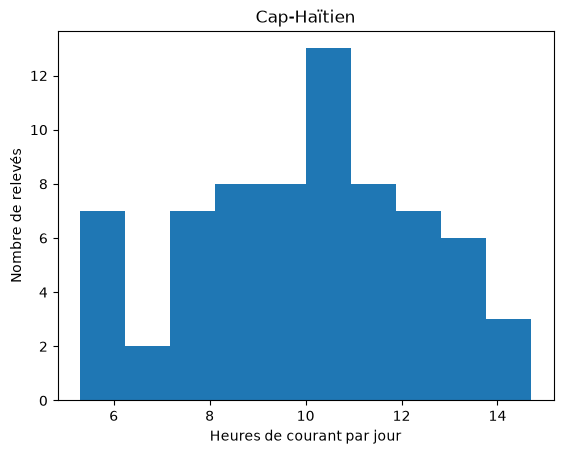

In [22]:
cap = avec_meteo[avec_meteo["commune"] == "Cap-Haïtien"]

plt.hist(cap["heures_courant"], bins=10)
plt.xlabel("Heures de courant par jour")
plt.ylabel("Nombre de relevés")
plt.title("Cap-Haïtien")
plt.show()

**Ce qu'on en conclut :**

Cap-Haïtien subit les coupures les plus longues avec une médiane de 10,0 heures de courant par jour, contre 11,6 à 11,9 heures ailleurs. De plus, on dénombre 3 relevés critiques en 2025 ayant moins de 8 heures de courant par jour, situés à Carénage, Delmas 33 et Rue 15.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [23]:
avec_meteo.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]

,mois,quartier,type,kwh
87,2025-07,Delmas 33,Commercial,742780.0
56,2024-11,Centre-ville,Commercial,597730.0
88,2025-09,Delmas 33,Commercial,591420.0


**Ce qu'on en conclut :**

C'est Delmas 33 qui décroche le record absolu avec 742 780 kWh en juillet 2025, suivi de près par le Centre-ville (597 730 kWh en novembre 2024). Ces chiffres prouvent que les zones commerciales ont des pics d'activité et des besoins énergétiques gigantesques qui dépassent largement la moyenne des autres quartiers.   

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

Monsieur le Directeur, la consommation électrique ne suit pas la chaleur (corrélation de -0,15) mais dépend fortement des heures de courant disponibles (corrélation de 0,76). Les abonnés consomment donc par opportunité dès que l'électricité est rétablie, plutôt qu'en fonction des variations de température extérieure. Néanmoins, rappelez-vous qu'une forte corrélation statistique met en évidence une tendance forte, mais elle ne prouve pas formellement un lien de cause à effet absolu

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.